In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/races.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructor_results.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/drivers.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructors.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/lap_times.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/status.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/driver_standings.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/seasons.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/pit_stops.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/sprint_results.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructor_standings.csv
/kaggle/input/datasets/rohanrao/formula

In [3]:
import pandas as pd

In [4]:
circuits =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/circuits.csv") 
constructor_results =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructor_results.csv") 
constructor_standings =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructor_standings.csv") 
constructors =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructors.csv") 
driver_standings =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/driver_standings.csv") 
drivers =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/drivers.csv") 
lap_times =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/lap_times.csv") 
pit_stops =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/pit_stops.csv") 
qualifying =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/qualifying.csv") 
races =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/races.csv") 
seasons =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/seasons.csv") 
sprint_results =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/sprint_results.csv") 
status =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/status.csv") 
results =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/results.csv") 

Circuits.CSV

In [5]:

circuits.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   circuitId   77 non-null     int64  
 1   circuitRef  77 non-null     object 
 2   name        77 non-null     object 
 3   location    77 non-null     object 
 4   country     77 non-null     object 
 5   lat         77 non-null     float64
 6   lng         77 non-null     float64
 7   alt         77 non-null     int64  
 8   url         77 non-null     object 
dtypes: float64(2), int64(2), object(5)
memory usage: 5.5+ KB


**no null values here ,so no need to change /N**

In [6]:
# Display every row and column.
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(circuits)

,circuitId,circuitRef,name,location,country,lat,lng,alt,url
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.84970,144.968000,10,http://en.wikipedia.org/wiki/Melbourne_Grand_P...
1,2,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.76083,101.738000,18,http://en.wikipedia.org/wiki/Sepang_Internatio...
2,3,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.03250,50.510600,7,http://en.wikipedia.org/wiki/Bahrain_Internati...
3,4,catalunya,Circuit de Barcelona-Catalunya,Montmeló,Spain,41.57000,2.261110,109,http://en.wikipedia.org/wiki/Circuit_de_Barcel...
4,5,istanbul,Istanbul Park,Istanbul,Turkey,40.95170,29.405000,130,http://en.wikipedia.org/wiki/Istanbul_Park
5,6,monaco,Circuit de Monaco,Monte-Carlo,Monaco,43.73470,7.420560,7,http://en.wikipedia.org/wiki/Circuit_de_Monaco
6,7,villeneuve,Circuit Gilles Villeneuve,Montreal,Canada,45.50000,-73.522800,13,http://en.wikipedia.org/wiki/Circuit_Gilles_Vi...
7,8,magny_cours,Circuit de Nevers Magny-Cours,Magny Cours,France,46.86420,3.163610,228,http://en.wikipedia.org/wiki/Circuit_de_Nevers...
8,9,silverstone,Silverstone Circuit,Silverstone,UK,52.07860,-1.016940,153,http://en.wikipedia.org/wiki/Silverstone_Circuit
9,10,hockenheimring,Hockenheimring,Hockenheim,Germany,49.32780,8.565830,103,http://en.wikipedia.org/wiki/Hockenheimring


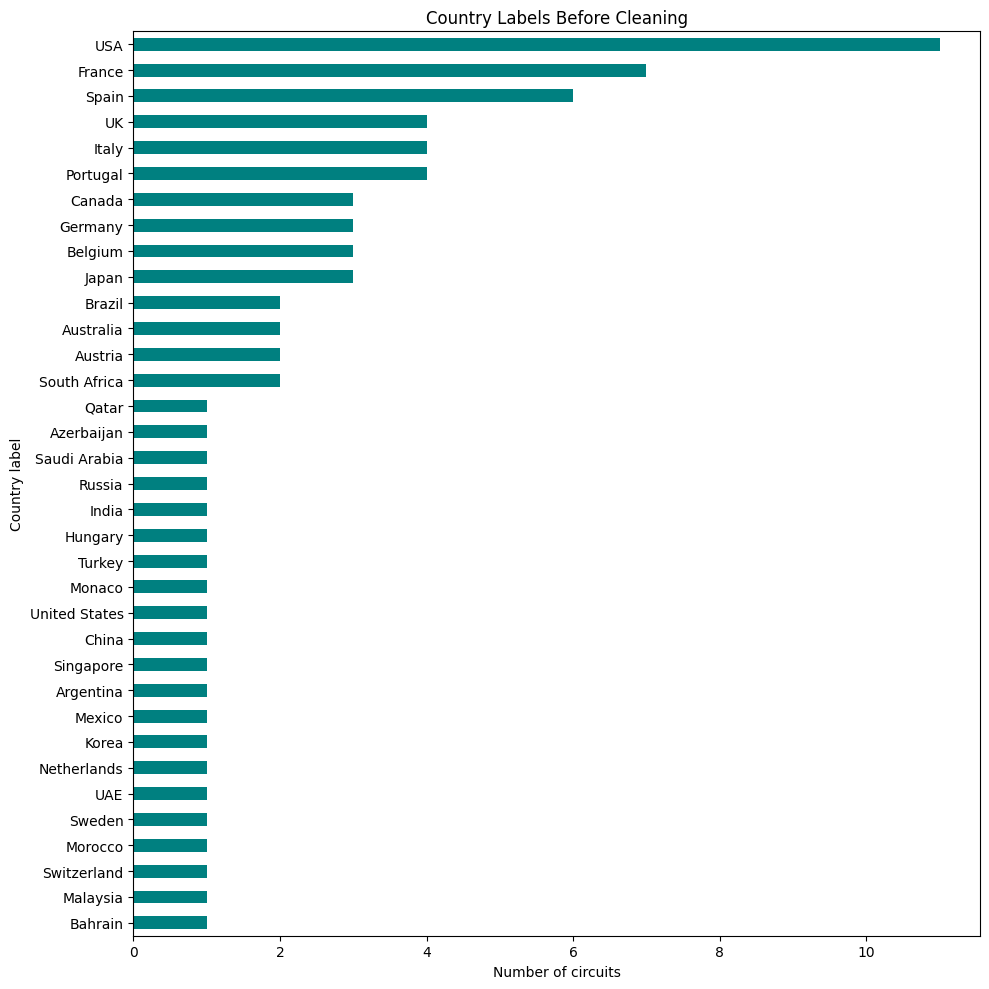

In [7]:
import matplotlib.pyplot as plt

counts = circuits["country"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(10, 10))

counts.plot.barh(ax=ax, color="teal")

ax.set_title("Country Labels Before Cleaning")
ax.set_xlabel("Number of circuits")
ax.set_ylabel("Country label")

plt.tight_layout()
plt.show()

In [8]:
# Create a cleaned copy; preserve the original circuits table.
circuits_clean = circuits.copy(deep=True)
# Standardize the country name.
circuits_clean["country"] = circuits_clean["country"].replace({
    "USA": "United States"
})

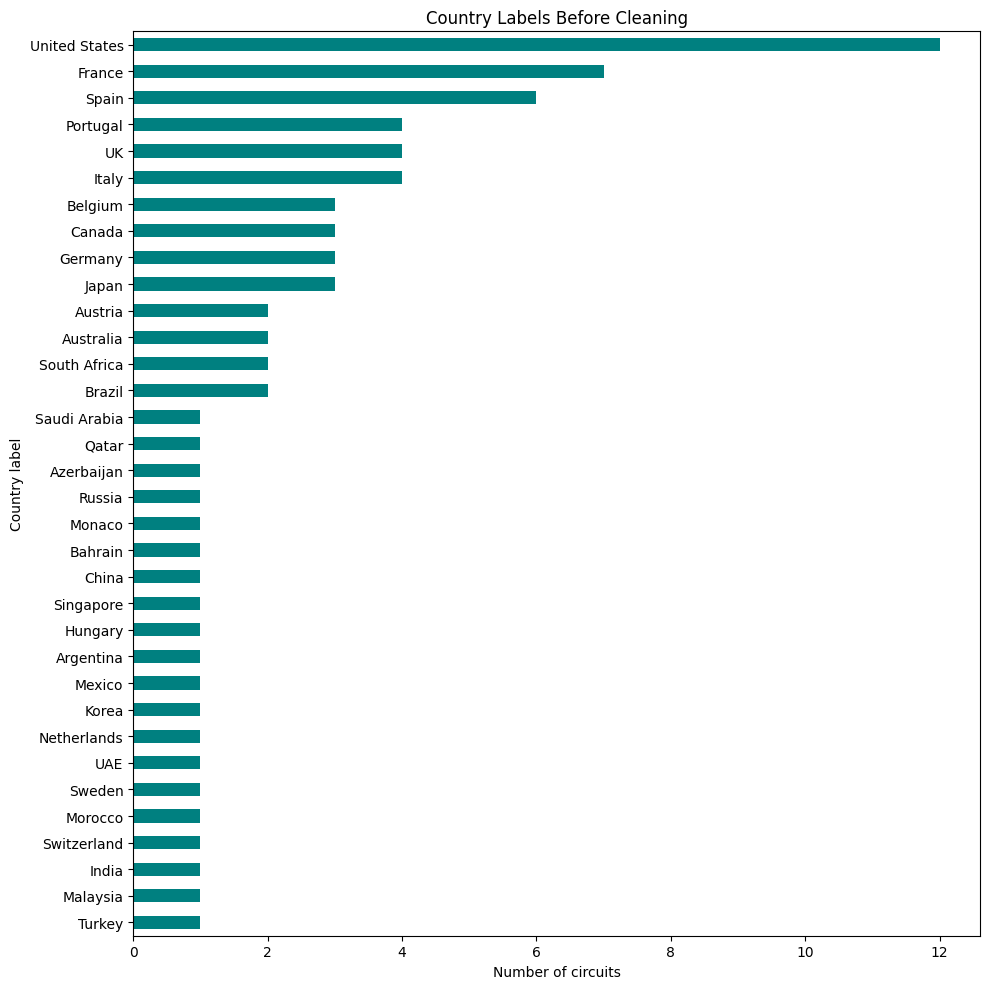

In [9]:
import matplotlib.pyplot as plt

counts = circuits_clean["country"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(10, 10))

counts.plot.barh(ax=ax, color="teal")

ax.set_title("Country Labels Before Cleaning")
ax.set_xlabel("Number of circuits")
ax.set_ylabel("Country label")

plt.tight_layout()
plt.show()

In [10]:
print("Missing circuit IDs:",
      circuits_clean["circuitId"].isna().sum())

print("Duplicate circuit IDs:",
      circuits_clean["circuitId"].duplicated().sum())

assert circuits_clean["circuitId"].notna().all(), "Missing circuit IDs found"
assert circuits_clean["circuitId"].is_unique, "Duplicate circuit IDs found"

print("Passed: circuitId is unique and non-null.")

Missing circuit IDs: 0
Duplicate circuit IDs: 0
Passed: circuitId is unique and non-null.


constructor_results.csv

In [11]:
constructor_results.head()

,constructorResultsId,raceId,constructorId,points,status
0,1,18,1,14.0,\N
1,2,18,2,8.0,\N
2,3,18,3,9.0,\N
3,4,18,4,5.0,\N
4,5,18,5,2.0,\N


In [12]:
constructor_results_clean  =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructor_results.csv",na_values=[r"\N"]) 
constructor_results_clean.head()

,constructorResultsId,raceId,constructorId,points,status
0,1,18,1,14.0,NaN
1,2,18,2,8.0,NaN
2,3,18,3,9.0,NaN
3,4,18,4,5.0,NaN
4,5,18,5,2.0,NaN


In [13]:
constructor_results_clean.isnull().sum()

constructorResultsId        0
raceId                      0
constructorId               0
points                      0
status                  12608
dtype: int64

In [14]:


display(
    constructor_results_clean["status"]
    .value_counts(dropna=False)
    .rename_axis("Status")
    .reset_index(name="Number of rows")
)

# Display the special flagged records.
display(
    constructor_results_clean.loc[
        constructor_results_clean["status"].notna()
    ]
)

,Status,Number of rows
0,NaN,12608
1,D,17


,constructorResultsId,raceId,constructorId,points,status
185,186,36,1,14.0,D
195,196,37,1,18.0,D
207,208,38,1,12.0,D
218,219,39,1,14.0,D
228,229,40,1,18.0,D
239,240,41,1,12.0,D
250,251,42,1,18.0,D
262,263,43,1,8.0,D
273,274,44,1,14.0,D
283,284,45,1,10.0,D


In [15]:
# Check the record ID.
record_id = "constructorResultsId"

print("Missing constructorResultsId:",
      constructor_results_clean[record_id].isna().sum())

print("Duplicate constructorResultsId:",
      constructor_results_clean[record_id].duplicated().sum())

assert constructor_results_clean[record_id].notna().all(), \
    "Missing constructorResultsId found"

assert constructor_results_clean[record_id].is_unique, \
    "Duplicate constructorResultsId found"


# Check the race–constructor combination.
pair_columns = ["raceId", "constructorId"]

print("\nMissing race and constructor IDs:")
display(constructor_results_clean[pair_columns].isna().sum())

print("Duplicate race–constructor pairs:",
      constructor_results_clean.duplicated(pair_columns).sum())

assert constructor_results_clean[pair_columns].notna().all().all(), \
    "Missing raceId or constructorId found"

assert not constructor_results_clean.duplicated(pair_columns).any(), \
    "Duplicate race–constructor pairs found"

print("\nPassed: record IDs and race–constructor pairs are unique and non-null.")

Missing constructorResultsId: 0
Duplicate constructorResultsId: 0

Missing race and constructor IDs:


raceId           0
constructorId    0
dtype: int64

Duplicate race–constructor pairs: 0

Passed: record IDs and race–constructor pairs are unique and non-null.


In [16]:
# Find rows with missing or unknown race IDs.
invalid_races = constructor_results_clean[
    constructor_results_clean["raceId"].isna()
    | ~constructor_results_clean["raceId"].isin(races["raceId"])
]

# Find rows with missing or unknown constructor IDs.
invalid_constructors = constructor_results_clean[
    constructor_results_clean["constructorId"].isna()
    | ~constructor_results_clean["constructorId"].isin(
        constructors["constructorId"]
    )
]

print("Rows with missing or unknown race IDs:", len(invalid_races))
print("Rows with missing or unknown constructor IDs:", len(invalid_constructors))

if not invalid_races.empty:
    display(invalid_races)

if not invalid_constructors.empty:
    display(invalid_constructors)

assert invalid_races.empty, \
    "Some race IDs are missing or absent from races"

assert invalid_constructors.empty, \
    "Some constructor IDs are missing or absent from constructors"

print("Passed: all race and constructor IDs exist in their reference tables.")

Rows with missing or unknown race IDs: 0
Rows with missing or unknown constructor IDs: 0
Passed: all race and constructor IDs exist in their reference tables.


Rezk

Mohamed 

# **Kareem** 

### **qualifying table**

In [29]:
print("shape:", qualifying.shape)
print("columns:", list(qualifying.columns))
qualifying.head()

shape: (10494, 9)
columns: ['qualifyId', 'raceId', 'driverId', 'constructorId', 'number', 'position', 'q1', 'q2', 'q3']


,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3
0,1,18,1,1,22,1,1:26.572,1:25.187,1:26.714
1,2,18,9,2,4,2,1:26.103,1:25.315,1:26.869
2,3,18,5,1,23,3,1:25.664,1:25.452,1:27.079
3,4,18,13,6,2,4,1:25.994,1:25.691,1:27.178
4,5,18,2,2,3,5,1:25.960,1:25.518,1:27.236


In [60]:
before = pd.DataFrame({
    "sentinel (\\N)": (qualifying == r"\N").sum(),
    "blank ('')":     (qualifying == "").sum(),
})
before["total missing"] = before.sum(axis=1)
before["% missing"] = (100 * before["total missing"] / len(qualifying)).round(2)
before

,sentinel (\N),blank (''),total missing,% missing
qualifyId,0,0,0,0.00
raceId,0,0,0,0.00
driverId,0,0,0,0.00
constructorId,0,0,0,0.00
number,0,0,0,0.00
position,0,0,0,0.00
q1,156,0,156,1.49
q2,4625,0,4625,44.07
q3,6819,0,6819,64.98


In [45]:
##removed placeholders to null values

qualifying_clean =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/qualifying.csv", na_values=[r"\N"]) 
qualifying_clean.head()

,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3
0,1,18,1,1,22,1,1:26.572,1:25.187,1:26.714
1,2,18,9,2,4,2,1:26.103,1:25.315,1:26.869
2,3,18,5,1,23,3,1:25.664,1:25.452,1:27.079
3,4,18,13,6,2,4,1:25.994,1:25.691,1:27.178
4,5,18,2,2,3,5,1:25.960,1:25.518,1:27.236


In [24]:
qualifying_clean.isnull().sum()

qualifyId           0
raceId              0
driverId            0
constructorId       0
number              0
position            0
q1                156
q2               4647
q3               6865
dtype: int64

In [46]:
check = pd.DataFrame({
    "missing_before": before["total missing"],
    "NaN_after": qualifying_clean.isnull().sum(),
})
check["match"] = check["missing_before"] == check["NaN_after"]
check

,missing_before,NaN_after,match
qualifyId,0,0,True
raceId,0,0,True
driverId,0,0,True
constructorId,0,0,True
number,0,0,True
position,0,0,True
q1,156,156,True
q2,4625,4647,False
q3,6819,6865,False


In [47]:
def to_seconds(t):
    if pd.isna(t):
        return np.nan
    minutes, seconds = str(t).split(":")
    return int(minutes) * 60 + float(seconds)

for col in ["q1", "q2", "q3"]:
    qualifying_clean[col + "_sec"] = qualifying_clean[col].map(to_seconds)

qualifying_clean[["q1", "q1_sec", "q2", "q2_sec", "q3", "q3_sec"]].head()

,q1,q1_sec,q2,q2_sec,q3,q3_sec
0,1:26.572,86.572,1:25.187,85.187,1:26.714,86.714
1,1:26.103,86.103,1:25.315,85.315,1:26.869,86.869
2,1:25.664,85.664,1:25.452,85.452,1:27.079,87.079
3,1:25.994,85.994,1:25.691,85.691,1:27.178,87.178
4,1:25.960,85.960,1:25.518,85.518,1:27.236,87.236


In [48]:
for col in ["q1", "q2", "q3"]:
    lost = (qualifying_clean[col].notna() & qualifying_clean[col + "_sec"].isna()).sum()
    print(col, "failed conversions:", lost)

q1 failed conversions: 0
q2 failed conversions: 0
q3 failed conversions: 0


In [49]:
n_dup = qualifying_clean.duplicated(subset=["raceId", "driverId"]).sum()
print("duplicate (raceId, driverId) pairs:", n_dup)

duplicate (raceId, driverId) pairs: 0


In [50]:
print("qualifyId unique  :", qualifying_clean["qualifyId"].is_unique)
print("qualifyId no nulls:", qualifying_clean["qualifyId"].notna().all())

qualifyId unique  : True
qualifyId no nulls: True


In [52]:
races_ids        = pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/races.csv", usecols=["raceId"])["raceId"]
drivers_ids      = pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/drivers.csv", usecols=["driverId"])["driverId"]
constructors_ids = pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructors.csv", usecols=["constructorId"])["constructorId"]

rows = []
for col, parent, ids in [("raceId", "races.raceId", races_ids),
                         ("driverId", "drivers.driverId", drivers_ids),
                         ("constructorId", "constructors.constructorId", constructors_ids)]:
    orphans = int((~qualifying_clean[col].dropna().isin(ids)).sum())
    rows.append({"foreign key": f"qualifying.{col}", "points to": parent,
                 "null values": int(qualifying_clean[col].isna().sum()),
                 "orphan rows": orphans, "ok": orphans == 0})
pd.DataFrame(rows)

,foreign key,points to,null values,orphan rows,ok
0,qualifying.raceId,races.raceId,0,0,True
1,qualifying.driverId,drivers.driverId,0,0,True
2,qualifying.constructorId,constructors.constructorId,0,0,True


### **races table**

In [56]:
print("shape:", races.shape)
print("columns:", list(races.columns))
races.head()

shape: (1125, 18)
columns: ['raceId', 'year', 'round', 'circuitId', 'name', 'date', 'time', 'url', 'fp1_date', 'fp1_time', 'fp2_date', 'fp2_time', 'fp3_date', 'fp3_time', 'quali_date', 'quali_time', 'sprint_date', 'sprint_time']


,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
3,4,2009,4,3,Bahrain Grand Prix,2009-04-26,12:00:00,http://en.wikipedia.org/wiki/2009_Bahrain_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
4,5,2009,5,4,Spanish Grand Prix,2009-05-10,12:00:00,http://en.wikipedia.org/wiki/2009_Spanish_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N


In [62]:
before_r = pd.DataFrame({"sentinel (\\N)": (races == r"\N").sum()})
before_r["% missing"] = (100 * before_r["sentinel (\\N)"] / len(races)).round(2)
before_r

,sentinel (\N),% missing
raceId,0,0.00
year,0,0.00
round,0,0.00
circuitId,0,0.00
name,0,0.00
date,0,0.00
time,731,64.98
url,0,0.00
fp1_date,1035,92.00
fp1_time,1057,93.96


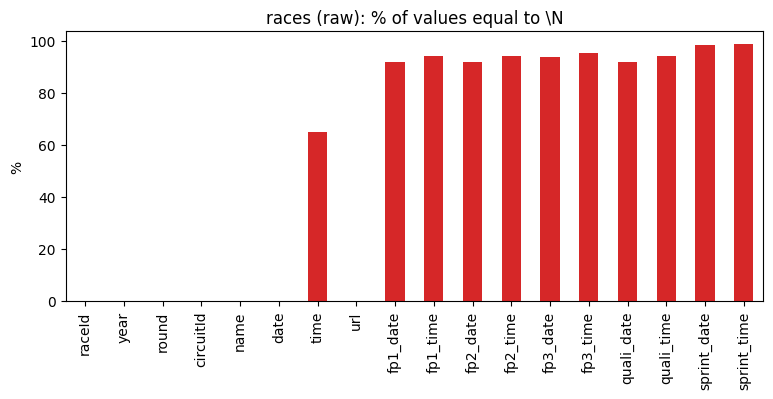

In [63]:
before_r["% missing"].plot(kind="bar", color="tab:red", figsize=(9, 3.5),
                           title="races (raw): % of values equal to \\N")
plt.ylabel("%")
plt.show()

In [65]:
races_clean = pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/races.csv", keep_default_na=False, na_values=[r"\N"])
races_clean.head()

,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,2009,4,3,Bahrain Grand Prix,2009-04-26,12:00:00,http://en.wikipedia.org/wiki/2009_Bahrain_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,2009,5,4,Spanish Grand Prix,2009-05-10,12:00:00,http://en.wikipedia.org/wiki/2009_Spanish_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [66]:
check_r = pd.DataFrame({"sentinel_before": before_r["sentinel (\\N)"],
                        "NaN_after": races_clean.isnull().sum()})
check_r["match"] = check_r["sentinel_before"] == check_r["NaN_after"]
check_r

,sentinel_before,NaN_after,match
raceId,0,0,True
year,0,0,True
round,0,0,True
circuitId,0,0,True
name,0,0,True
date,0,0,True
time,731,731,True
url,0,0,True
fp1_date,1035,1035,True
fp1_time,1057,1057,True


In [68]:
date_cols = [c for c in ["date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"]
             if c in races_clean.columns]

for col in date_cols:
    n_before = races_clean[col].isna().sum()
    races_clean[col] = pd.to_datetime(races_clean[col], errors="coerce")
    print(col, "| new missing values created:", races_clean[col].isna().sum() - n_before)

races_clean[date_cols].dtypes

date | new missing values created: 0
fp1_date | new missing values created: 0
fp2_date | new missing values created: 0
fp3_date | new missing values created: 0
quali_date | new missing values created: 0
sprint_date | new missing values created: 0


date           datetime64[ns]
fp1_date       datetime64[ns]
fp2_date       datetime64[ns]
fp3_date       datetime64[ns]
quali_date     datetime64[ns]
sprint_date    datetime64[ns]
dtype: object

In [69]:
n_before = races_clean["time"].isna().sum()
races_clean["race_start_time"] = pd.to_timedelta(races_clean["time"])
print("new missing values created:", races_clean["race_start_time"].isna().sum() - n_before)
races_clean[["time", "race_start_time"]].dropna().head()

new missing values created: 0


,time,race_start_time
0,06:00:00,0 days 06:00:00
1,09:00:00,0 days 09:00:00
2,07:00:00,0 days 07:00:00
3,12:00:00,0 days 12:00:00
4,12:00:00,0 days 12:00:00


In [70]:
print("raceId unique  :", races_clean["raceId"].is_unique)
print("raceId no nulls:", races_clean["raceId"].notna().all())
print("(year, round) unique:", not races_clean.duplicated(["year", "round"]).any())

raceId unique  : True
raceId no nulls: True
(year, round) unique: True


In [72]:
circuits_ids = pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/circuits.csv", usecols=["circuitId"])["circuitId"]
seasons_ids  = pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/seasons.csv", usecols=["year"])["year"]

rows = []
for col, parent, ids in [("circuitId", "circuits.circuitId", circuits_ids),
                         ("year", "seasons.year", seasons_ids)]:
    orphans = int((~races_clean[col].dropna().isin(ids)).sum())
    rows.append({"foreign key": f"races.{col}", "points to": parent,
                 "null values": int(races_clean[col].isna().sum()),
                 "orphan rows": orphans, "ok": orphans == 0})
pd.DataFrame(rows)

,foreign key,points to,null values,orphan rows,ok
0,races.circuitId,circuits.circuitId,0,0,True
1,races.year,seasons.year,0,0,True


In [73]:
print("raceId order matches date order:", races_clean.sort_values("raceId")["date"].is_monotonic_increasing)

rounds = races_clean.groupby("year")["round"].agg(n_races="count", first="min", last="max")
rounds["gap"] = rounds["last"] - rounds["n_races"]
print("seasons with a gap or not starting at round 1:")
rounds[(rounds["first"] != 1) | (rounds["gap"] != 0)]

raceId order matches date order: False
seasons with a gap or not starting at round 1:


,n_races,first,last,gap
year,,,,


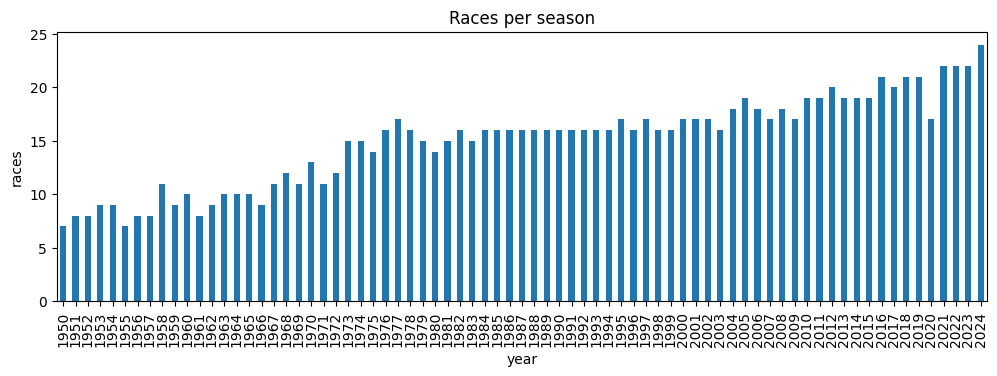

In [74]:
races_clean.groupby("year").size().plot(kind="bar", figsize=(12, 3.5), title="Races per season")
plt.ylabel("races")
plt.show()

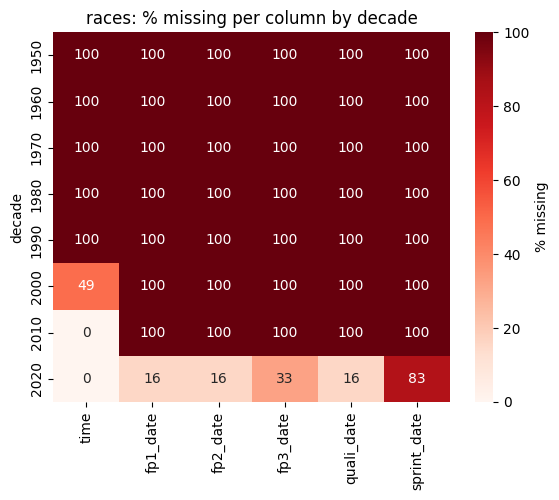

In [75]:
import seaborn as sns

sched = [c for c in ["time", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"]
         if c in races_clean.columns]
miss_dec = (races_clean.assign(decade=(races_clean["year"] // 10) * 10)
                       .groupby("decade")[sched]
                       .apply(lambda d: d.isna().mean() * 100))

sns.heatmap(miss_dec, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% missing"})
plt.title("races: % missing per column by decade")
plt.show()

In [67]:
pd.DataFrame({
    "rows": [len(races), len(races_clean)],
    "columns": [races.shape[1], races_clean.shape[1]],
    "missing values": [int(before_r["sentinel (\\N)"].sum()), int(races_clean.isnull().sum().sum())],
    "text '\\N' left": [int(before_r["sentinel (\\N)"].sum()), 0],
}, index=["before", "after"])

,rows,columns,missing values,text '\N' left
before,1125,18,11349,11349
after,1125,18,11349,0


### **Results table** 

In [76]:
print("shape:", results.shape)
print("columns:", list(results.columns))
results.head()

shape: (26759, 18)
columns: ['resultId', 'raceId', 'driverId', 'constructorId', 'number', 'grid', 'position', 'positionText', 'positionOrder', 'points', 'laps', 'time', 'milliseconds', 'fastestLap', 'rank', 'fastestLapTime', 'fastestLapSpeed', 'statusId']


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22,1,1,1,1,10.0,58,1:34:50.616,5690616,39,2,1:27.452,218.300,1
1,2,18,2,2,3,5,2,2,2,8.0,58,+5.478,5696094,41,3,1:27.739,217.586,1
2,3,18,3,3,7,7,3,3,3,6.0,58,+8.163,5698779,41,5,1:28.090,216.719,1
3,4,18,4,4,5,11,4,4,4,5.0,58,+17.181,5707797,58,7,1:28.603,215.464,1
4,5,18,5,1,23,3,5,5,5,4.0,58,+18.014,5708630,43,1,1:27.418,218.385,1


The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


In [77]:
before_res = pd.DataFrame({"sentinel (\\N)": (results == r"\N").sum()})
before_res["% missing"] = (100 * before_res["sentinel (\\N)"] / len(results)).round(2)
before_res

,sentinel (\N),% missing
resultId,0,0.00
raceId,0,0.00
driverId,0,0.00
constructorId,0,0.00
number,6,0.02
grid,0,0.00
position,10953,40.93
positionText,0,0.00
positionOrder,0,0.00
points,0,0.00


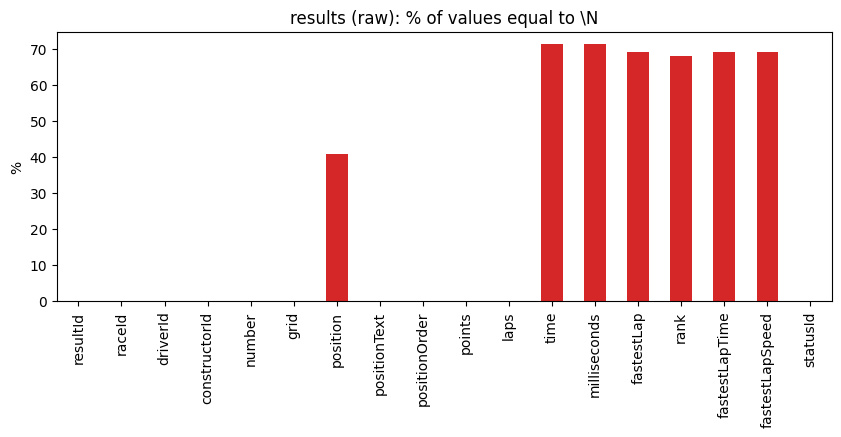

In [78]:
before_res["% missing"].plot(kind="bar", color="tab:red", figsize=(10, 3.5),
                             title="results (raw): % of values equal to \\N")
plt.ylabel("%")
plt.show()

In [79]:
results_clean = pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/results.csv", keep_default_na=False, na_values=[r"\N"])
results_clean.head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22.0,1,1.0,1,1,10.0,58,1:34:50.616,5690616.0,39.0,2.0,1:27.452,218.300,1
1,2,18,2,2,3.0,5,2.0,2,2,8.0,58,+5.478,5696094.0,41.0,3.0,1:27.739,217.586,1
2,3,18,3,3,7.0,7,3.0,3,3,6.0,58,+8.163,5698779.0,41.0,5.0,1:28.090,216.719,1
3,4,18,4,4,5.0,11,4.0,4,4,5.0,58,+17.181,5707797.0,58.0,7.0,1:28.603,215.464,1
4,5,18,5,1,23.0,3,5.0,5,5,4.0,58,+18.014,5708630.0,43.0,1.0,1:27.418,218.385,1


In [80]:
check_res = pd.DataFrame({"sentinel_before": before_res["sentinel (\\N)"],
                          "NaN_after": results_clean.isnull().sum()})
check_res["match"] = check_res["sentinel_before"] == check_res["NaN_after"]
check_res

,sentinel_before,NaN_after,match
resultId,0,0,True
raceId,0,0,True
driverId,0,0,True
constructorId,0,0,True
number,6,6,True
grid,0,0,True
position,10953,10953,True
positionText,0,0,True
positionOrder,0,0,True
points,0,0,True


In [81]:
results_clean["fastestLapTime_sec"] = results_clean["fastestLapTime"].map(to_seconds)

lost = (results_clean["fastestLapTime"].notna() & results_clean["fastestLapTime_sec"].isna()).sum()
print("failed conversions:", lost)
results_clean[["fastestLapTime", "fastestLapTime_sec"]].dropna().head()

failed conversions: 0


,fastestLapTime,fastestLapTime_sec
0,1:27.452,87.452
1,1:27.739,87.739
2,1:28.090,88.090
3,1:28.603,88.603
4,1:27.418,87.418


In [82]:
results_clean[["time", "milliseconds"]].dropna().head(10)

,time,milliseconds
0,1:34:50.616,5690616.0
1,+5.478,5696094.0
2,+8.163,5698779.0
3,+17.181,5707797.0
4,+18.014,5708630.0
22,1:31:18.555,5478555.0
23,+19.570,5498125.0
24,+38.450,5517005.0
25,+45.832,5524387.0
26,+46.548,5525103.0


In [83]:
print("positionOrder missing:", results_clean["positionOrder"].isna().sum(), "(must be 0)")
print("positionOrder < 1    :", (results_clean["positionOrder"] < 1).sum(), "(must be 0)")
print("grid range:", results_clean["grid"].min(), "->", results_clean["grid"].max())
print("negative points:", (results_clean["points"] < 0).sum())

positionOrder missing: 0 (must be 0)
positionOrder < 1    : 0 (must be 0)
grid range: 0 -> 34
negative points: 0


In [84]:
n_dup = results_clean.duplicated(subset=["raceId", "driverId"]).sum()
print("extra rows (same driver twice in the same race):", n_dup)

extra rows (same driver twice in the same race): 91


In [85]:
dup_rows = results_clean[results_clean.duplicated(["raceId", "driverId"], keep=False)].sort_values(["raceId", "driverId", "resultId"])
print("rows involved:", len(dup_rows))
dup_rows[["resultId", "raceId", "driverId", "constructorId", "grid", "positionOrder", "points", "laps", "statusId"]].head(20)

rows involved: 176


,resultId,raceId,driverId,constructorId,grid,positionOrder,points,laps,statusId
13188,13189,540,229,54,0,26,0.0,0,81
13191,13192,540,229,57,0,29,0.0,0,97
17362,17363,717,373,172,1,7,0.0,102,60
24298,24304,717,373,172,1,12,0.0,54,98
17740,17741,733,465,172,0,22,0.0,0,54
17743,17744,733,465,97,0,25,0.0,0,54
17961,17962,742,475,102,20,19,0.0,56,2
17963,17964,742,475,172,5,21,0.0,44,23
18062,18063,745,418,172,11,17,0.0,23,6
24297,24303,745,418,172,15,11,0.0,92,18


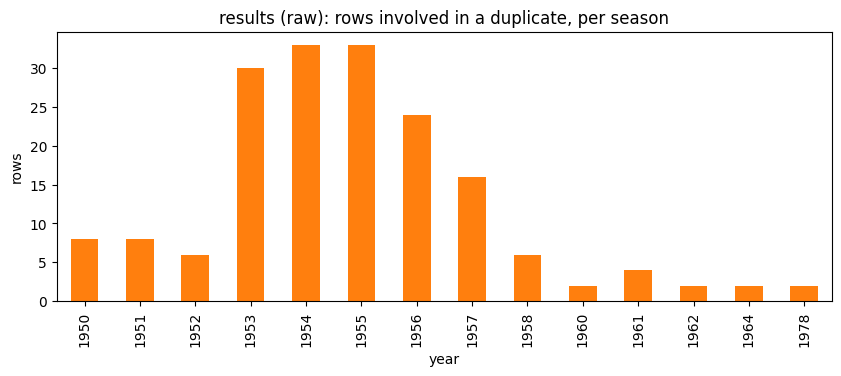

number of started rows per duplicated pair:


grid
2    76
3     6
0     3
Name: count, dtype: int64

In [94]:
years = pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/races.csv", usecols=["raceId", "year"])
dup_plot = dup_rows.merge(years, on="raceId", how="left")     # copy for plotting only

dup_plot.groupby("year").size().plot(kind="bar", color="tab:orange", figsize=(10, 3.5),
                                     title="results (raw): rows involved in a duplicate, per season")
plt.ylabel("rows")
plt.show()

# In how many duplicated pairs did exactly one of the rows start from a real grid slot (grid > 0)?
started_per_pair = dup_rows.groupby(["raceId", "driverId"])["grid"].apply(lambda g: (g > 0).sum())
print("number of started rows per duplicated pair:")
started_per_pair.value_counts()

In [95]:
results_clean["started"] = results_clean["grid"] > 0

results_clean = (results_clean
                 .sort_values(["raceId", "driverId", "started", "resultId"], ascending=[True, True, False, True])
                 .drop_duplicates(["raceId", "driverId"], keep="first")
                 .drop(columns="started")
                 .sort_values("resultId")
                 .reset_index(drop=True))

print("rows after:", len(results_clean), "| removed:", len(results) - len(results_clean))

rows after: 26668 | removed: 91


In [96]:
assert not results_clean.duplicated(["raceId", "driverId"]).any()
print("OK: (raceId, driverId) is unique")

OK: (raceId, driverId) is unique


In [97]:
print("resultId unique  :", results_clean["resultId"].is_unique)
print("resultId no nulls:", results_clean["resultId"].notna().all())

resultId unique  : True
resultId no nulls: True


In [98]:
races_ids        = pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/races.csv", usecols=["raceId"])["raceId"]
drivers_ids      = pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/drivers.csv", usecols=["driverId"])["driverId"]
constructors_ids = pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructors.csv", usecols=["constructorId"])["constructorId"]
status_ids       = pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/status.csv", usecols=["statusId"])["statusId"]

rows = []
for col, parent, ids in [("raceId", "races.raceId", races_ids),
                         ("driverId", "drivers.driverId", drivers_ids),
                         ("constructorId", "constructors.constructorId", constructors_ids),
                         ("statusId", "status.statusId", status_ids)]:
    orphans = int((~results_clean[col].dropna().isin(ids)).sum())
    rows.append({"foreign key": f"results.{col}", "points to": parent,
                 "null values": int(results_clean[col].isna().sum()),
                 "orphan rows": orphans, "ok": orphans == 0})
pd.DataFrame(rows)

,foreign key,points to,null values,orphan rows,ok
0,results.raceId,races.raceId,0,0,True
1,results.driverId,drivers.driverId,0,0,True
2,results.constructorId,constructors.constructorId,0,0,True
3,results.statusId,status.statusId,0,0,True


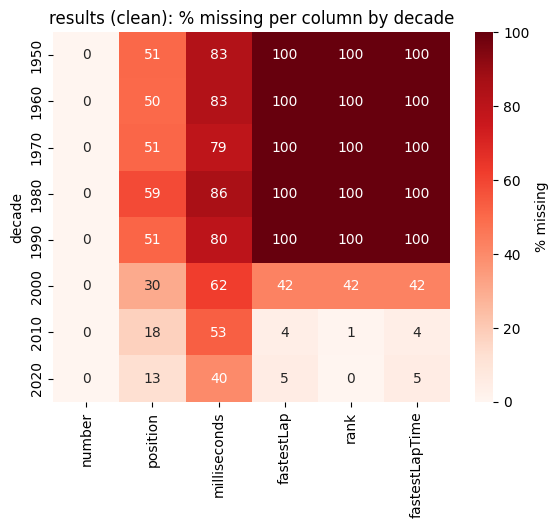

In [99]:
import seaborn as sns

res_year = results_clean.merge(years, on="raceId", how="left")     # copy for plotting only
cols = ["number", "position", "milliseconds", "fastestLap", "rank", "fastestLapTime"]
miss_dec = (res_year.assign(decade=(res_year["year"] // 10) * 10)
                    .groupby("decade")[cols]
                    .apply(lambda d: d.isna().mean() * 100))

sns.heatmap(miss_dec, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% missing"})
plt.title("results (clean): % missing per column by decade")
plt.show()

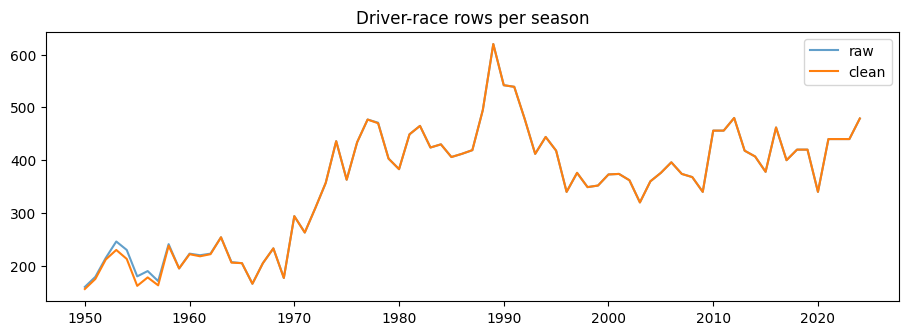

In [100]:
before_rows = pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/results.csv", usecols=["raceId"]).merge(years, on="raceId").groupby("year").size()
after_rows  = res_year.groupby("year").size()

plt.figure(figsize=(11, 3.5))
plt.plot(before_rows.index, before_rows.values, label="raw", alpha=0.7)
plt.plot(after_rows.index, after_rows.values, label="clean")
plt.title("Driver-race rows per season")
plt.legend()
plt.show()

In [101]:
pd.DataFrame({
    "rows": [len(results), len(results_clean)],
    "columns": [results.shape[1], results_clean.shape[1]],
    "missing values": [int(before_res["sentinel (\\N)"].sum()), int(results_clean.isnull().sum().sum())],
    "text '\\N' left": [int(before_res["sentinel (\\N)"].sum()), 0],
    "duplicate (raceId, driverId)": [n_dup, 0],
}, index=["before", "after"])

,rows,columns,missing values,text '\N' left,"duplicate (raceId, driverId)"
before,26759,18,122887,122887,91
after,26668,19,140755,0,0


Hamza